In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Intel Image Classification.zip to Intel Image Classification.zip


In [10]:
dataset_path='/content/intel_data/Intel Image Classification'

dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224, 224),
    batch_size=32
)
print("Classes : " , dataset.class_names)

Found 12632 files belonging to 6 classes.
Classes :  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [11]:
train_size = int(0.8 * len(dataset))
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size)

print("dataset split complete")

dataset split complete


In [13]:
base_model = tf.keras.applications.VGG16(
    weights = 'imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
print("VGG16 loaded")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded


In [15]:
for layer in base_model.layers:
  layer.trainable=False
print("layers frozen")

layers frozen


In [16]:
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(6, activation='softmax')
]
)
print("Cusotom layers added ")

Cusotom layers added 


In [17]:
model.compile(
    optimizer='adam',loss='sparse_categorical_crossentropy', metrics=['accuracy']
)
print("Model compiled")

Model compiled


In [19]:
history = model.fit(
    train_ds,
    validation_data = test_ds,
    epochs=5
)

Epoch 1/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 67s 192ms/step - accuracy: 0.8433 - loss: 0.5417 - val_accuracy: 0.8766 - val_loss: 0.3620
Epoch 2/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 61s 192ms/step - accuracy: 0.9013 - loss: 0.2790 - val_accuracy: 0.8917 - val_loss: 0.3212
Epoch 3/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 63s 201ms/step - accuracy: 0.9265 - loss: 0.2031 - val_accuracy: 0.8889 - val_loss: 0.3417
Epoch 4/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 63s 200ms/step - accuracy: 0.9430 - loss: 0.1627 - val_accuracy: 0.8806 - val_loss: 0.3837
Epoch 5/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 64s 201ms/step - accuracy: 0.9526 - loss: 0.1382 - val_accuracy: 0.8956 - val_loss: 0.3334


In [20]:
loss, accuracy = model.evaluate(test_ds)
print("test loss : " , loss)
print("Test accuracy : ", accuracy)

79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.8960 - loss: 0.3316
test loss :  0.3316411077976227
Test accuracy :  0.8960317373275757


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step


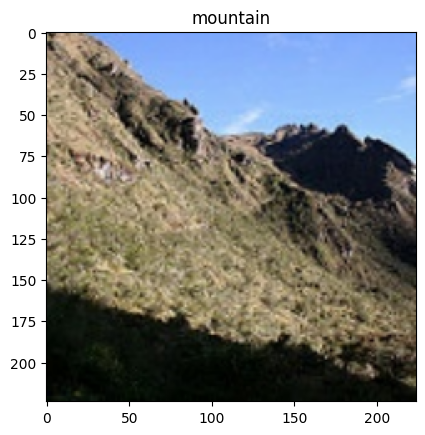

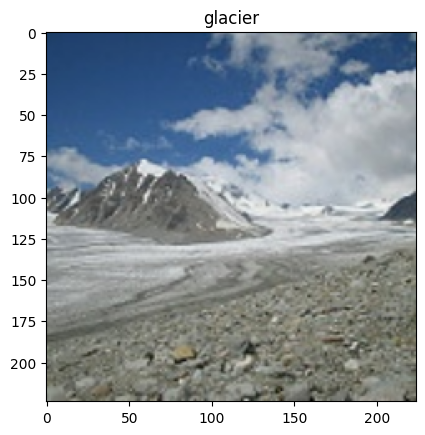

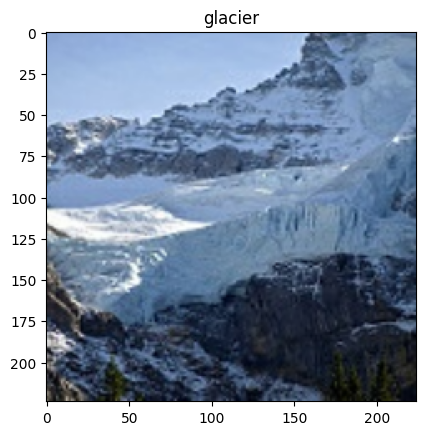

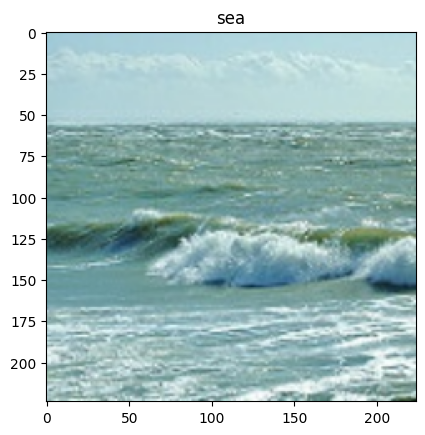

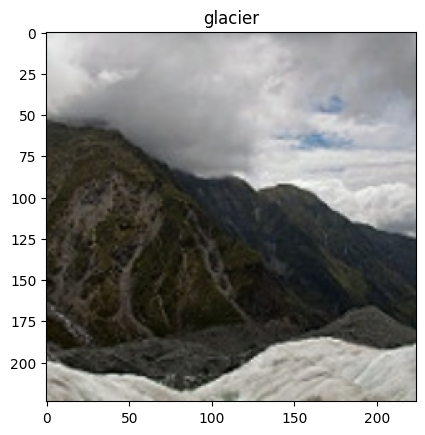

In [22]:
images, labels = next(iter(test_ds))
predictions = model.predict(images)

for i in range(5):
  plt.imshow(images[i].numpy().astype("uint8"))
  plt.title(dataset.class_names[np.argmax(predictions[i])])
  plt.show()

In [23]:
for layer in base_model.layers[-4:]:
  layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(train_ds, validation_data=test_ds, epochs=2)

Epoch 1/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 78s 230ms/step - accuracy: 0.8992 - loss: 0.3009 - val_accuracy: 0.8881 - val_loss: 0.3213
Epoch 2/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 71s 224ms/step - accuracy: 0.9442 - loss: 0.1555 - val_accuracy: 0.9194 - val_loss: 0.2491


In [24]:
loss, accuracy = model.evaluate(test_ds)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 118ms/step - accuracy: 0.9190 - loss: 0.2530
Test Loss: 0.2530202567577362
Test Accuracy: 0.9190475940704346
